# DeepSea Exploration with RND and Bootstrap Ensembles

Portfolio packaging for Behrad Mazaheri. Original course/template credits below are retained; individual contributions are unverified.

**Static review only; no cells executed.** Historical outputs are preserved, not independently reproduced. Read README and REVIEW before citing results. Source cell indices in documentation are zero-based before this banner.

Three student helper modules are recovered verbatim from writefile cells under extracted_helpers/hw. They do not replace the missing course framework or environment. Four-seed comparisons and broad intervals are historical evidence, not a strong statistical ranking. Imports may require additional dependencies defined by the unavailable framework.


# Deep Exploration: RND vs Bootstrapped DQN on DeepSea

In hard-exploration tasks, reward is sparse and only a long, *specific* sequence
of actions ever reaches it. Naive ε-greedy dithering finds that sequence with
probability that shrinks exponentially in the horizon. **Deep exploration** means
committing to a coherent, multi-step plan to reach the unknown frontier. This
homework compares two classic deep-exploration agents on the **DeepSea**
benchmark, on a normal board and on a *noisy-TV* variant.

### Random Network Distillation (RND) — *novelty by prediction error*
- A **frozen random target** network `f̄(s)` maps states to an embedding and is never trained.
- A **predictor** `f(s)` is trained to match `f̄` on visited states; its error is large on novel states.
- The per-state **intrinsic bonus** — how far the predictor's embedding sits from the target's — is added to the reward, pulling the agent toward unfamiliar states.

### Bootstrapped DQN with randomized priors — *novelty by disagreement*
- An **ensemble of K heads**, each a trainable Q-net plus a *frozen randomized prior*, expresses value uncertainty.
- **Bootstrap masks** give each head a different sample of the data, keeping the heads diverse.
- **Posterior sampling**: one head is drawn per episode and followed greedily — approximate Thompson sampling, exploration *without* ε-greedy noise.

### Papers
- RND — Burda et al. 2018: https://arxiv.org/abs/1810.12894
- Bootstrapped DQN — Osband et al. 2016: https://arxiv.org/abs/1602.04621
- Randomized prior functions — Osband et al. 2018: https://arxiv.org/abs/1806.03335
- DeepSea / bsuite — Osband et al. 2019: https://arxiv.org/abs/1908.03568

### What you will do
1. Implement one **exploration metric** (coverage + entropy).
2. Build the networks/ensemble and implement the learning cores of **RND** and **Bootstrapped DQN**.
3. Quickly test each implementation on a small DeepSea.
4. Run the full **normal vs noisy** comparison and inspect the figures.
5. Answer the analysis questions.

You edit **three short files** — `hw/student_metric.py`, `hw/student_rnd.py`,
and `hw/student_bootstrap.py` — one per section (B, C, D), each through its
own `%%writefile` cell. Everything else is provided.

### Grading (100 pts)
The homework is worth **100 points**: **70** for the implementations and **30** for
the analysis questions.

- **Implementations (70)** — Section B *(8)*, Section C *(28)*, Section D *(34)*.
- **Analysis questions (30)** — Section G.

Each function and each question shows its exact share next to it.

### Submitting
Set **`STUDENT_NUMBER`** at the top of the Setup section — it is written into
`submission.zip`. Then run the notebook top to bottom. The final cell writes
**`submission.zip`** (< 10 MB: your implementation fingerprints + the run
records). Submit that file together with this notebook.

## Setup

In [2]:
# ============================================================
#  STUDENT NUMBER -- fill this in before running the notebook.
#  It is stamped into every training run and into submission.zip,
#  so we can confirm you ran the notebook yourself.
# ============================================================
STUDENT_NUMBER = "[student ID removed]"  # <-- replace with your student number

assert STUDENT_NUMBER.strip(), "Set STUDENT_NUMBER (top of the Setup cell) before running."

import importlib
import sys

%matplotlib inline

# Make the provided modules in hw/ importable.
sys.path.insert(0, "hw")

import numpy as np
import torch

# The three files you edit, one per section. Re-import each after its
# %%writefile cell with importlib.reload (each section shows how).
import student_metric
import student_rnd
import student_bootstrap

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", DEVICE)


def set_seed(seed: int) -> None:
    # Seed Python, NumPy and torch for reproducible cells.
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

torch 2.7.1+cu126 | device: cuda


## Section A — DeepSea and the noisy TV

**DeepSea** is an `N×N` grid. The agent starts at the top-left and is **forced to
descend exactly one row per step**, so every episode is exactly `N` steps. In each
column a fixed (per-column randomized) mapping decides which of the two raw
actions means *go right*. Going right costs a tiny penalty; the only large reward
(**+1**) sits in the **bottom-right** cell. Reaching the treasure requires
choosing *right* on every single step — an ε-greedy explorer stumbles onto it
with probability `2⁻ᴺ`. Only the **lower triangle** (column ≤ row) is reachable.
The *always-right* policy is the reference (solved) return, `1 − 0.01 = 0.99`.

**Noisy-TV variant.** Setting `ds_noise_dim = d > 0` appends `d` extra observation
features that carry **fresh uniform random noise while — and only while — the
agent sits in a designated column** (by default column 0, the left wall, the
*opposite* side from the treasure); elsewhere those features are zero. This noise
is **action-independent and reward-irrelevant**: it changes nothing about the
dynamics or the optimal policy. It is a localized "noisy television".

The two boards below are identical except for those left-wall noise features.

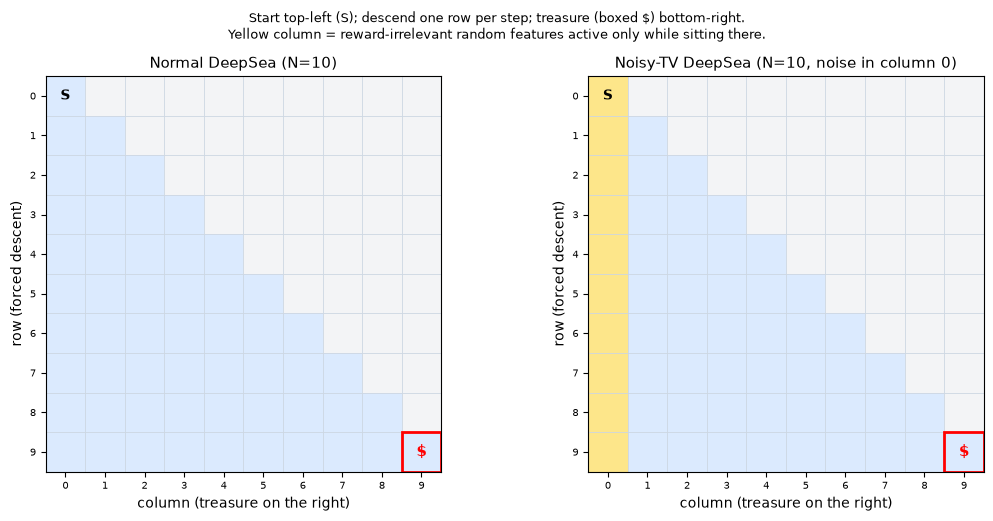

In [3]:
import hw_plots

SIZE = 10  # DeepSea side length N used throughout
hw_plots.show_demo_boards(SIZE)

## Section B — Exploration metric *(you implement — 8 pts)*

We measure exploration over the **reachable** cells with two quantities,
snapshotted periodically during training:

- **Coverage** — the fraction of reachable cells visited at least once (breadth).
- **Visitation entropy (bits)** — the Shannon entropy of the visit distribution
  over the reachable cells. High coverage *and* high entropy means broad, even
  exploration; low entropy means the agent keeps revisiting a few cells.

Implement **`coverage_entropy`** **(8 pts)** in the `%%writefile hw/student_metric.py`
cell below, then run that cell **and** the check cell under it. It is the only
function for this section.

In [4]:
%%writefile hw/student_metric.py
"""Section B of the homework: the exploration metric.

Edit this file through this ``%%writefile hw/student_metric.py`` cell, then re-run
it and ``importlib.reload(student_metric)`` (the check cell below) to pick up your
edits without restarting the kernel.
"""

from __future__ import annotations

import numpy as np


def coverage_entropy(
    visit_counts: "np.ndarray", reachable_mask: "np.ndarray"
) -> tuple[float, float]:
    """Summarise how much of the map was explored, and how evenly.

    Two scalars over the cells that *can* be reached (``reachable_mask``); cells
    outside that mask never count.

    Args:
        visit_counts: ``(N, N)`` int array -- how often each grid cell was visited.
        reachable_mask: ``(N, N)`` bool array -- the cells that count toward both
            numbers.

    Returns:
        ``(coverage, entropy_bits)``:

        * **coverage** -- the share of reachable cells visited at least once
          (``0.0`` when none, ``1.0`` when all). A breadth measure.
        * **entropy_bits** -- the Shannon entropy, in *bits*, of the visit
          distribution over the reachable cells: large when visits are spread
          evenly, small when the agent keeps revisiting a few cells. Define it as
          ``0.0`` when nothing reachable has been visited yet.
    """
    counts = np.asarray(visit_counts)
    mask = np.asarray(reachable_mask, dtype=bool)

    if counts.shape != mask.shape:
        raise ValueError(
            "visit_counts and reachable_mask must have the same shape; "
            f"got {counts.shape} and {mask.shape}"
        )

    reachable_counts = counts[mask].astype(np.float64, copy=False)
    if reachable_counts.size == 0:
        return 0.0, 0.0

    coverage = float(np.mean(reachable_counts > 0))
    total_visits = float(reachable_counts.sum())
    if total_visits <= 0.0:
        return coverage, 0.0

    probabilities = reachable_counts / total_visits
    positive = probabilities > 0.0
    entropy_bits = float(
        -np.sum(probabilities[positive] * np.log2(probabilities[positive]))
    )
    return coverage, entropy_bits


Overwriting hw/student_metric.py


In [5]:
# Reload so the modules that call student_metric pick up your latest edits.
importlib.reload(student_metric)

# Unit-check coverage_entropy on a small hand-built grid.
from metrics import reachable_mask

_counts = np.array([
    [4, 0, 0, 0],
    [2, 2, 0, 0],
    [0, 1, 1, 0],
    [0, 0, 0, 0],
], dtype=np.int64)
_reach = reachable_mask(4)              # lower triangle: 1+2+3+4 = 10 cells
cov, ent = student_metric.coverage_entropy(_counts, _reach)
print(f"coverage={cov:.4f}  entropy={ent:.4f} bits")

# 5 of 10 reachable cells visited.
assert abs(cov - 0.5) < 1e-9, cov
# Entropy of [4,2,2,1,1]/10 over the visited cells.
_p = np.array([4, 2, 2, 1, 1]) / 10
_expected = float(-(_p * np.log2(_p)).sum())
assert abs(ent - _expected) < 1e-9, (ent, _expected)
print("coverage_entropy OK")

coverage=0.5000  entropy=2.1219 bits
coverage_entropy OK


## Section C — Random Network Distillation *(you implement — 28 pts)*

RND scores a state's novelty by how badly a trained **predictor** reproduces the
output of a frozen random **target** on it; that error is added to the reward as an
exploration bonus and fades as a state becomes familiar (see the intro and Burda et
al. 2018).

**Action selection is provided** — RND acts with the same standard ε-greedy policy
as plain DQN — so you implement only its learning core, in the
`%%writefile hw/student_rnd.py` cell below:

- **`build_rnd_networks`** **(8 pts)** — you build the two embedding networks
  yourself: a frozen random **target** and a trainable **predictor**, each an
  `nn.Module` mapping an observation to an `output_dim` embedding. The target must
  never train; the architectures are yours.
- **`rnd_intrinsic_bonus`** **(10 pts)** — the per-state novelty bonus (detached,
  normalised via `agent.intrinsic_rms`) and the predictor's regression loss
  (differentiable).
- **`rnd_td_target`** **(6 pts)** — the Double-DQN target on the *shaped* reward.
- **`rnd_q_loss`** **(4 pts)** — the critic loss: `Q(s, a)` for the actions taken
  vs. your `rnd_td_target`.

Run that cell, then the reload + quick-test cell below it (it trains RND on a small
DeepSea and checks it reaches the treasure; `recorder=None`, so the metric is not
needed here).

In [6]:
%%writefile hw/student_rnd.py
"""Section C of the homework: Random Network Distillation (RND).

Edit this file through this ``%%writefile hw/student_rnd.py`` cell, then re-run it
and ``importlib.reload(student_rnd)`` (the quick-test cell below) to pick up your
edits without restarting the kernel.

**Action selection is provided** -- RND acts with the same standard epsilon-greedy
behaviour policy as plain DQN, so you implement only the RND-specific learning core
below.

Conventions used throughout this file:

* ``obs`` -- a flattened observation vector; ``obs_size`` is its length.
* ``B`` -- the batch size (number of transitions in a minibatch).
* ``rms`` -- a running mean/std tracker (``common.RunningMeanStd``): an online
  estimator of the mean and standard deviation of a stream of numbers.
"""

from __future__ import annotations

from typing import TYPE_CHECKING

import torch
import torch.nn as nn
import torch.nn.functional as F

if TYPE_CHECKING:
    from rnd_dqn import RNDDoubleDQN


def _mlp(
    input_dim: int, output_dim: int, hidden_sizes: tuple[int, ...]
) -> nn.Sequential:
    """Construct a small fully-connected ReLU network."""
    layers: list[nn.Module] = []
    last_dim = input_dim
    for hidden_dim in hidden_sizes:
        layers.extend((nn.Linear(last_dim, hidden_dim), nn.ReLU()))
        last_dim = hidden_dim
    layers.append(nn.Linear(last_dim, output_dim))
    return nn.Sequential(*layers)


def build_rnd_networks(
    obs_size: int, output_dim: int, hidden_sizes: tuple[int, ...]
) -> tuple[nn.Module, nn.Module]:
    """Build the two networks RND compares to measure novelty.

    RND scores novelty by how well a *trained predictor* reproduces the output of a
    *fixed random target* on a state: familiar states are easy to predict, novel
    ones are not.

    Args:
        obs_size: length of a flattened observation -- the input width both
            networks must accept (they are called on a ``(B, obs_size)`` tensor).
        output_dim: width of the embedding both networks must emit (their output
            is ``(B, output_dim)``).
        hidden_sizes: a suggested hidden-layer shape, e.g. ``(64, 64)``. Only a
            hint -- you are free to ignore it.

    Returns:
        ``(target, predictor)``, two ``torch.nn.Module`` objects that each map a
        ``(B, obs_size)`` float tensor to a ``(B, output_dim)`` embedding:

        * **target** -- a randomly initialised network that is *never trained*. Its
          parameters must not receive gradients (set ``requires_grad=False`` on
          them) so it stays a fixed, arbitrary function of the state.
        * **predictor** -- a trainable network, regressed toward the target on
          visited states elsewhere in the code.

        Build them however you like -- any architecture works as long as it
        respects the shape contract; a small multi-layer perceptron is the usual
        choice. The two networks need not share an architecture (giving the
        predictor a different, e.g. smaller, capacity is legitimate), but their
        outputs must be the same width so they are directly comparable.
    """
    target = _mlp(obs_size, output_dim, hidden_sizes)
    predictor = _mlp(obs_size, output_dim, hidden_sizes)

    for parameter in target.parameters():
        parameter.requires_grad_(False)

    return target, predictor


def rnd_intrinsic_bonus(
    agent: "RNDDoubleDQN", next_obs: "torch.Tensor"
) -> tuple["torch.Tensor", "torch.Tensor"]:
    """Novelty bonus for the landed-in states, and the predictor's training loss.

    Args:
        agent: the RND agent. The pieces you need:

            * ``agent.rnd_target`` -- the frozen target network you built.
            * ``agent.rnd_predictor`` -- the trainable predictor you built.
            * ``agent.intrinsic_rms`` -- a running mean/std tracker for the raw
              novelty scores. Call ``agent.intrinsic_rms.update(arr)`` with a 1-D
              NumPy array to fold a new batch into the statistics, and read
              ``agent.intrinsic_rms.std`` (a float) for the current standard
              deviation.
        next_obs: ``(B, obs_size)`` batch of states the agent just stepped into.

    Returns:
        ``(intrinsic, predictor_loss)``:

        * **intrinsic** -- a ``(B,)`` tensor, one novelty score per state, measuring
          how far the predictor's embedding sits from the target's. It feeds the
          reward, so it must be **detached** from the autograd graph and kept on a
          stable scale: first update ``agent.intrinsic_rms`` with this batch's raw
          scores, then divide the scores by ``agent.intrinsic_rms.std`` (guard
          against division by zero).
        * **predictor_loss** -- a single **differentiable** scalar that, when
          minimised, pulls the predictor toward the frozen target on ``next_obs``.
    """
    with torch.no_grad():
        target_embedding = agent.rnd_target(next_obs)
    predictor_embedding = agent.rnd_predictor(next_obs)

    # Mean squared embedding error gives one novelty score per state.
    raw_error = (predictor_embedding - target_embedding).pow(2).mean(dim=1)
    predictor_loss = raw_error.mean()

    detached_error = raw_error.detach()
    agent.intrinsic_rms.update(detached_error.cpu().numpy())
    normalizer = max(float(agent.intrinsic_rms.std), 1e-8)
    intrinsic = detached_error / normalizer
    return intrinsic, predictor_loss


def rnd_td_target(
    agent: "RNDDoubleDQN",
    shaped_reward: "torch.Tensor",
    next_obs: "torch.Tensor",
    done: "torch.Tensor",
) -> "torch.Tensor":
    """The Double-DQN bootstrap target (TD = temporal difference), on the shaped reward.

    Standard Double DQN: the *online* network (``agent.online``) chooses the next
    action, the *target* network (``agent.target``) supplies its value, and a
    terminal transition (``done``) contributes no future value. Discount with
    ``agent.cfg.gamma``; build it under ``torch.no_grad()`` (it is a fixed
    regression target, not something you backpropagate through).

    Args:
        agent: the RND agent (use ``agent.online``, ``agent.target``,
            ``agent.cfg.gamma``).
        shaped_reward: ``(B,)`` reward already combining extrinsic + intrinsic.
        next_obs: ``(B, obs_size)`` next states.
        done: ``(B,)`` float terminal flags (1.0 = terminal, 0.0 = not).

    Returns:
        A ``(B,)`` tensor of bootstrap targets, with no gradient attached.
    """
    with torch.no_grad():
        next_action = agent.online(next_obs).argmax(dim=1, keepdim=True)
        next_q = agent.target(next_obs).gather(1, next_action).squeeze(1)
        return shaped_reward + agent.cfg.gamma * (1.0 - done) * next_q


def rnd_q_loss(
    agent: "RNDDoubleDQN",
    obs: "torch.Tensor",
    action: "torch.Tensor",
    shaped_reward: "torch.Tensor",
    next_obs: "torch.Tensor",
    done: "torch.Tensor",
) -> "torch.Tensor":
    """The Double-DQN critic loss for RND, on the shaped reward.

    Take ``Q(s, a)`` from ``agent.online`` for the actions actually taken, build the
    bootstrap target with your :func:`rnd_td_target` on ``shaped_reward``, and
    return the Huber (smooth-L1) loss between them.

    Args:
        agent: the RND agent (use ``agent.online``).
        obs: ``(B, obs_size)`` states.
        action: ``(B,)`` long tensor of actions taken.
        shaped_reward, next_obs, done: as passed to :func:`rnd_td_target`.

    Returns:
        A single differentiable scalar loss.
    """
    chosen_q = agent.online(obs).gather(1, action.long().unsqueeze(1)).squeeze(1)
    target = rnd_td_target(agent, shaped_reward, next_obs, done)
    return F.smooth_l1_loss(chosen_q, target)


Overwriting hw/student_rnd.py


In [7]:
import rnd_dqn
importlib.reload(student_rnd)  # ensure your latest student_rnd is in use

set_seed(0)
qt_steps = 15_000
cfg = rnd_dqn.Config(
    size=6, total_steps=qt_steps, seed=0, device=DEVICE,
    run_name="quicktest_rnd", checkpoint_every=qt_steps,
    epsilon_decay_steps=int(0.8 * qt_steps), intrinsic_coef=1.0,
)
agent = rnd_dqn.run_training(cfg, recorder=None)

# Greedy rollout: with a correct RND the agent should now run right to the treasure.
env = agent.env.clone()
obs, _ = env.reset(seed=0)
ret = 0.0
for _ in range(env.size):
    a = agent.select_action(obs, epsilon=0.0)
    step = env.step(a)
    obs, ret = step.observation, ret + step.reward
print(f"RND greedy return = {ret:.3f}  (reference {env.reference_return:.3f})")
assert ret >= 0.8 * env.reference_return, "RND did not solve N=6 — check your implementation"
print("RND quick test OK")

DeepSea(N=6) reference_return=0.9900 intrinsic_coef=1.0 device=cuda
step    5000 | episodes   833 | eps 0.604 | int_std  0.0005 | mean100 return  0.0955 | reference 0.9900 | time 0:00:17
step   10000 | episodes  1666 | eps 0.208 | int_std  0.0003 | mean100 return  0.5030 | reference 0.9900 | time 0:00:39
step   15000 | episodes  2500 | eps 0.050 | int_std  0.0003 | mean100 return  0.8807 | reference 0.9900 | time 0:01:01
  checkpoint -> checkpoints\quicktest_rnd\step_00015000.pt
RND greedy return = 0.990  (reference 0.990)
RND quick test OK


## Section D — Bootstrapped DQN *(you implement — 34 pts)*

Bootstrapped DQN explores by **disagreement**: an ensemble of independently
initialised value heads (each plus a frozen randomized prior) disagrees about
states the data has not pinned down. One head is sampled per episode and followed
greedily — approximate Thompson sampling, with no ε-greedy noise (see the intro and
Osband et al. 2016/2018).

Implement the following in the `%%writefile hw/student_bootstrap.py` cell below:

- **`build_bootstrap_ensemble`** **(10 pts)** — you build the `num_heads` ensemble
  heads yourself. Each head is an `nn.Module` pairing a trainable network with a
  *frozen randomized prior*, output `Q_k(s) = trainable_k(s) + prior_scale · prior_k(s)`.
  Independent random init is what makes the heads disagree.
- **`boot_sample_head`** **(3 pts)** — posterior sampling: pick the single head to
  follow for the next episode (the only exploration mechanism).
- **`boot_select_action`** **(4 pts)** — greedy action under that one head (the
  behaviour policy during an episode).
- **`boot_eval_action`** **(5 pts)** — the *evaluation* policy: greedy under the
  ensemble-**mean** Q.
- **`boot_head_target`** **(6 pts)** — the per-head Double-DQN target.
- **`boot_head_loss`** **(6 pts)** — the masked per-head loss: `Q(s, a)` vs. your
  `boot_head_target`, averaged over the head's bootstrap-masked transitions.

Run that cell, then the reload + quick-test cell below it.

In [8]:
%%writefile hw/student_bootstrap.py
"""Section D of the homework: Bootstrapped DQN with randomized priors.

Edit this file through this ``%%writefile hw/student_bootstrap.py`` cell, then
re-run it and ``importlib.reload(student_bootstrap)`` (the quick-test cell below)
to pick up your edits without restarting the kernel.

Conventions used throughout this file:

* ``obs`` -- a flattened observation vector; ``obs_size`` is its length.
* ``B`` -- the batch size (number of transitions in a minibatch).
* ``K`` -- the ensemble size (number of value heads), i.e. ``agent.cfg.num_heads``.
"""

from __future__ import annotations

from typing import TYPE_CHECKING

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

if TYPE_CHECKING:
    from bootstrap_dqn import BootstrappedDQN


def _mlp(
    input_dim: int, output_dim: int, hidden_sizes: tuple[int, ...]
) -> nn.Sequential:
    """Construct a fully-connected ReLU network."""
    layers: list[nn.Module] = []
    last_dim = input_dim
    for hidden_dim in hidden_sizes:
        layers.extend((nn.Linear(last_dim, hidden_dim), nn.ReLU()))
        last_dim = hidden_dim
    layers.append(nn.Linear(last_dim, output_dim))
    return nn.Sequential(*layers)


class RandomizedPriorHead(nn.Module):
    """One trainable Q-network plus an independent frozen randomized prior."""

    def __init__(
        self,
        obs_size: int,
        num_actions: int,
        prior_scale: float,
        hidden_sizes: tuple[int, ...],
    ) -> None:
        super().__init__()
        self.trainable = _mlp(obs_size, num_actions, hidden_sizes)
        self.prior = _mlp(obs_size, num_actions, hidden_sizes)
        self.prior_scale = float(prior_scale)
        for parameter in self.prior.parameters():
            parameter.requires_grad_(False)

    def forward(self, obs: torch.Tensor) -> torch.Tensor:
        return self.trainable(obs) + self.prior_scale * self.prior(obs)


def build_bootstrap_ensemble(
    obs_size: int,
    num_actions: int,
    num_heads: int,
    prior_scale: float,
    hidden_sizes: tuple[int, ...],
) -> "nn.ModuleList":
    """Build the ensemble of value heads that powers Bootstrapped DQN.

    Bootstrapped DQN explores by *disagreement*: independently initialised heads
    disagree about states the data has not pinned down, and that disagreement drives
    deep exploration. Each head pairs a trainable network with a *frozen randomized
    prior* -- a second, randomly initialised network that is never trained. The head
    outputs their sum::

        Q_k(s) = trainable_k(s) + prior_scale * prior_k(s)

    The frozen prior injects a persistent, per-head source of disagreement that
    ordinary weight initialisation would otherwise wash out as the heads fit the
    same data.

    Args:
        obs_size: length of a flattened observation -- each head's input width
            (heads are called on a ``(B, obs_size)`` tensor).
        num_actions: number of Q-values each head outputs (its output is
            ``(B, num_actions)``).
        num_heads: ``K`` -- how many independent heads to build.
        prior_scale: the weight on each head's frozen prior in the sum above.
        hidden_sizes: a suggested hidden-layer shape, e.g. ``(64, 64)``. Only a
            hint -- you are free to ignore it.

    Returns:
        A ``torch.nn.ModuleList`` of ``num_heads`` heads. Each head is a
        ``torch.nn.Module`` mapping ``(B, obs_size)`` to ``(B, num_actions)`` and
        combining a trainable network with a frozen prior as above. Requirements:

        * The prior's parameters must **not** receive gradients
          (``requires_grad=False``) -- the agent's optimizer trains only the
          parameters that still require gradients, leaving the priors fixed.
        * The heads must be **independent** (each gets its own fresh random init, so
          they start out diverse) but **share the same architecture**, so a target
          copy of the ensemble can mirror it parameter-for-parameter via
          ``load_state_dict``.

        Build the heads however you like as long as they meet this contract.
    """
    return nn.ModuleList(
        [
            RandomizedPriorHead(
                obs_size=obs_size,
                num_actions=num_actions,
                prior_scale=prior_scale,
                hidden_sizes=hidden_sizes,
            )
            for _ in range(num_heads)
        ]
    )


def boot_sample_head(agent: "BootstrappedDQN", rng: "np.random.Generator") -> int:
    """Pick which ensemble head to act with for the next episode.

    This is the posterior-sampling step (approximate Thompson sampling): commit to a
    single head and follow it greedily for a whole episode, which is what makes the
    exploration *deep* (coherent over many steps) instead of dithering.

    Args:
        agent: the Bootstrapped-DQN agent (the ensemble has ``agent.cfg.num_heads``
            heads).
        rng: a NumPy random generator to draw from (use it, not the global RNG, so
            the run is reproducible).

    Returns:
        A single head index, an ``int`` in ``[0, agent.cfg.num_heads)``, drawn
        uniformly at random.
    """
    return int(rng.integers(agent.cfg.num_heads))


def boot_select_action(agent: "BootstrappedDQN", obs: "np.ndarray", head: int) -> int:
    """Greedy action under one ensemble head -- Bootstrapped DQN's behaviour policy.

    During an episode the agent commits to the single sampled ``head`` and acts
    greedily under it (there is no epsilon-greedy noise).

    Args:
        agent: the Bootstrapped-DQN agent. ``agent.ensemble`` is the
            ``torch.nn.ModuleList`` of heads you built; ``agent.device`` is the
            torch device the heads live on.
        obs: a single ``(obs_size,)`` observation (not a batch).
        head: index of the head to act with.

    Returns:
        The greedy action (an ``int``): the argmax over ``agent.ensemble[head]``'s
        Q-values for ``obs``.
    """
    obs_tensor = torch.as_tensor(obs, dtype=torch.float32, device=agent.device)
    with torch.no_grad():
        q_values = agent.ensemble[head](obs_tensor.unsqueeze(0))
    return int(q_values.argmax(dim=1).item())


def boot_eval_action(agent: "BootstrappedDQN", obs: "np.ndarray") -> int:
    """Greedy action for *evaluation*: act on the ensemble's mean Q.

    Training samples one head per episode (that is the exploration); at evaluation
    time you exploit the whole posterior instead -- average the Q-values across every
    head in the ensemble and take the argmax.

    Args:
        agent: the Bootstrapped-DQN agent (use ``agent.ensemble`` and
            ``agent.device``).
        obs: a single ``(obs_size,)`` observation (not a batch).

    Returns:
        The greedy action (an ``int``) under the mean Q-values across all heads.
    """
    obs_tensor = torch.as_tensor(obs, dtype=torch.float32, device=agent.device)
    with torch.no_grad():
        per_head_q = torch.stack(
            [head(obs_tensor.unsqueeze(0)) for head in agent.ensemble], dim=0
        )
        mean_q = per_head_q.mean(dim=0)
    return int(mean_q.argmax(dim=1).item())


def boot_head_target(
    agent: "BootstrappedDQN",
    online_k: "nn.Module",
    target_k: "nn.Module",
    reward: "torch.Tensor",
    next_obs: "torch.Tensor",
    done: "torch.Tensor",
) -> "torch.Tensor":
    """The Double-DQN bootstrap target for a single ensemble head.

    Same Double-DQN rule as :func:`student_rnd.rnd_td_target`, but per head: this
    head's *online* network ``online_k`` selects the next action and its *target*
    copy ``target_k`` evaluates it; terminal transitions get no future value;
    discount with ``agent.cfg.gamma``; build it under ``torch.no_grad()``.

    Args:
        agent: the Bootstrapped-DQN agent (use ``agent.cfg.gamma``).
        online_k: this head's online network.
        target_k: this head's target copy.
        reward: ``(B,)`` rewards.
        next_obs: ``(B, obs_size)`` next states.
        done: ``(B,)`` float terminal flags (1.0 = terminal, 0.0 = not).

    Returns:
        A ``(B,)`` tensor of bootstrap targets for this head, with no gradient
        attached.
    """
    with torch.no_grad():
        next_action = online_k(next_obs).argmax(dim=1, keepdim=True)
        next_q = target_k(next_obs).gather(1, next_action).squeeze(1)
        return reward + agent.cfg.gamma * (1.0 - done) * next_q


def boot_head_loss(
    agent: "BootstrappedDQN",
    online_k: "nn.Module",
    target_k: "nn.Module",
    obs: "torch.Tensor",
    action: "torch.Tensor",
    reward: "torch.Tensor",
    next_obs: "torch.Tensor",
    done: "torch.Tensor",
    mask: "torch.Tensor",
) -> "torch.Tensor":
    """The masked Double-DQN loss for one ensemble head.

    For this head: take ``Q(s, a)`` from ``online_k`` for the actions taken, build
    the per-head target with your :func:`boot_head_target`, and return the Huber
    (smooth-L1) loss averaged over **only** the transitions whose bootstrap ``mask``
    bit is set. The caller skips heads with an all-zero mask, so ``mask.sum() > 0``.

    Args:
        agent: the Bootstrapped-DQN agent.
        online_k: this head's online network.
        target_k: this head's target copy.
        obs: ``(B, obs_size)`` states.
        action: ``(B,)`` long tensor of actions taken.
        reward, next_obs, done: as passed to :func:`boot_head_target`.
        mask: ``(B,)`` float tensor of 0/1 bootstrap-mask bits selecting this head's
            transitions.

    Returns:
        A single differentiable scalar: the mean Huber loss over this head's masked
        transitions.
    """
    chosen_q = online_k(obs).gather(1, action.long().unsqueeze(1)).squeeze(1)
    target = boot_head_target(agent, online_k, target_k, reward, next_obs, done)
    per_transition_loss = F.smooth_l1_loss(chosen_q, target, reduction="none")
    mask = mask.to(dtype=per_transition_loss.dtype)
    return (per_transition_loss * mask).sum() / mask.sum().clamp_min(1.0)


Overwriting hw/student_bootstrap.py


In [9]:
import bootstrap_dqn
importlib.reload(student_bootstrap)

set_seed(0)
cfg = bootstrap_dqn.Config(
    size=6, total_steps=8_000, seed=0, device=DEVICE,
    run_name="quicktest_boot", checkpoint_every=8_000,
    num_heads=5, prior_scale=3.0, mask_prob=0.5,
)
agent = bootstrap_dqn.run_training(cfg, recorder=None)

env = agent.env.clone()
obs, _ = env.reset(seed=0)
ret = 0.0
for _ in range(env.size):
    a = agent.select_action(obs, head=0)
    step = env.step(a)
    obs, ret = step.observation, ret + step.reward
print(f"Bootstrap head-0 greedy return = {ret:.3f}  (reference {env.reference_return:.3f})")
assert ret >= 0.8 * env.reference_return, "Bootstrap did not solve N=6 — check your implementation"
print("Bootstrap quick test OK")

DeepSea(N=6) reference_return=0.9900 heads=5 prior_scale=3.0 device=cuda
step    5000 | episodes   833 | heads  5 | mean100 return  0.9916 | reference 0.9900 | time 0:01:02
  checkpoint -> checkpoints\quicktest_boot\step_00008000.pt
Bootstrap head-0 greedy return = 0.992  (reference 0.990)
Bootstrap quick test OK


## Section E — Full comparison: normal vs noisy DeepSea

This trains **both agents** across **multiple seeds** on the normal board and on
the noisy-TV board, threading your metric through every run, then runs the full
analysis. The sweep is **resumable** — re-running skips finished runs — and trains
runs concurrently (`WORKERS`).

The config cell separates **experiment settings** from **algorithm
hyperparameters**:

- **Experiment settings** — `SIZE`, `SEEDS`, `TOTAL_STEPS`, `NOISE_DIM`,
  `NOISE_COLUMNS`. **Leave these at their given values in the run you submit**, so
  every submission is compared on exactly the same task.
- **Algorithm hyperparameters** — `NUM_HEADS`, `PRIOR_SCALE`, `MASK_PROB`,
  `INTRINSIC_COEF`, `RND_OUTPUT_DIM`. These are yours to **tune**.

While exploring you may lower `TOTAL_STEPS` / `SEEDS` for a faster, noisier pass —
just restore the given experiment settings for your final submitted run.

In [10]:
import hw_experiment

# --- experiment configuration ---
# Experiment settings: KEEP THESE AT THEIR GIVEN VALUES IN THE RUN YOU SUBMIT.
# (You may change them while exploring, but your submitted sweep must use these.)
SIZE          = 15
SEEDS         = (0, 1, 2, 42)
TOTAL_STEPS   = 20_000
NOISE_DIM     = 15
NOISE_COLUMNS = (0,)

# Algorithm hyperparameters: you MAY tune these.
NUM_HEADS      = 5
PRIOR_SCALE    = 3.0
MASK_PROB      = 0.5
INTRINSIC_COEF = 1.0
RND_OUTPUT_DIM = 64

# Runtime only (no effect on results): set to your hardware.
WORKERS    = 4
EXP_DEVICE = DEVICE

hw_experiment.run_full_comparison(
    size=SIZE, seeds=SEEDS, total_steps=TOTAL_STEPS, device=EXP_DEVICE,
    workers=WORKERS, num_heads=NUM_HEADS, prior_scale=PRIOR_SCALE,
    mask_prob=MASK_PROB, intrinsic_coef=INTRINSIC_COEF,
    rnd_output_dim=RND_OUTPUT_DIM, noise_dim=NOISE_DIM, noise_columns=NOISE_COLUMNS,
)


===== NORMAL DeepSea (N=15) =====
experiment[deepsea]: 3 agents x 1 sizes x 4 seeds = 12 runs, 20000 steps each, workers=4
    ... still training: 0/12 runs done (30s elapsed)
    ... still training: 0/12 runs done (60s elapsed)
[1/12] double_dqn n=15 seed=42: saved results\normal\runs\double_dqn\n15_seed42.npz
[2/12] double_dqn n=15 seed=1: saved results\normal\runs\double_dqn\n15_seed1.npz
[3/12] double_dqn n=15 seed=0: saved results\normal\runs\double_dqn\n15_seed0.npz
[4/12] double_dqn n=15 seed=2: saved results\normal\runs\double_dqn\n15_seed2.npz
    ... still training: 4/12 runs done (104s elapsed)
    ... still training: 4/12 runs done (134s elapsed)
    ... still training: 4/12 runs done (164s elapsed)
[5/12] rnd_dqn n=15 seed=0: saved results\normal\runs\rnd_dqn\n15_seed0.npz
[6/12] rnd_dqn n=15 seed=2: saved results\normal\runs\rnd_dqn\n15_seed2.npz
[7/12] rnd_dqn n=15 seed=1: saved results\normal\runs\rnd_dqn\n15_seed1.npz
[8/12] rnd_dqn n=15 seed=42: saved results\normal\

## Section F — Results and plots

The figures below come from the two sweeps. Compare the agents **within** each
board, and compare each agent **across** the two boards.

################  NORMAL DeepSea  ################
--- learning + coverage: results/normal ---


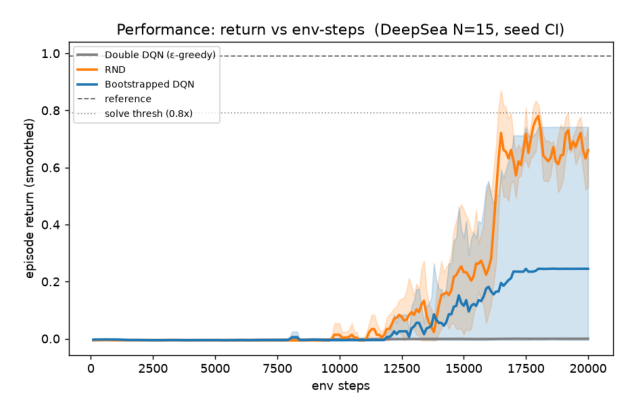

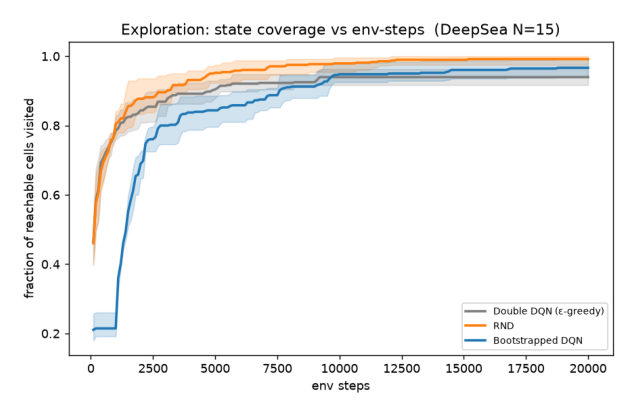

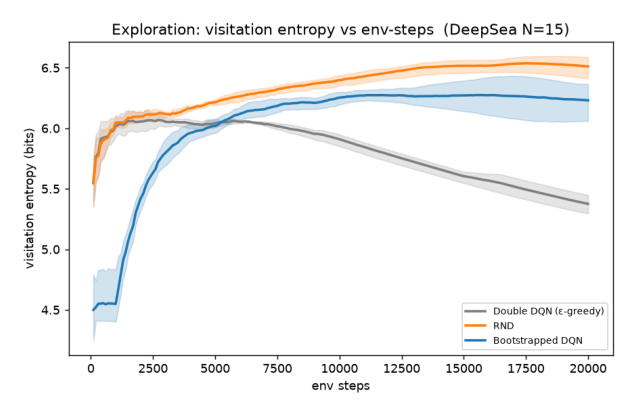

--- visitation heatmaps: results/normal ---


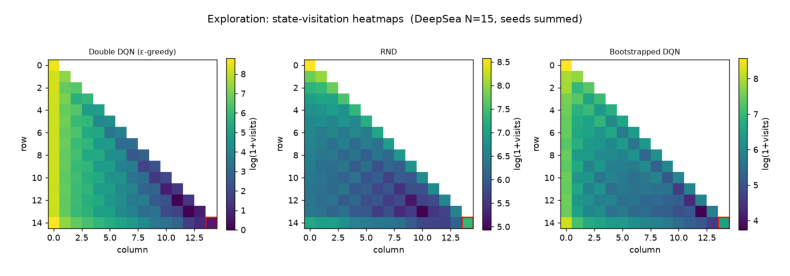

--- statistical rigor: results/normal ---


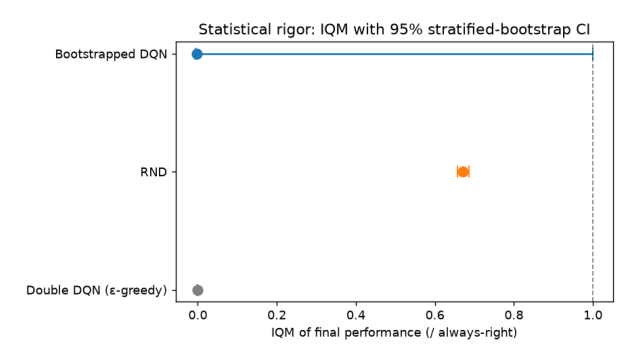

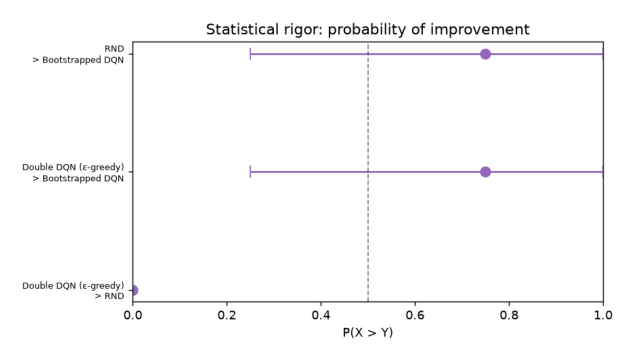

In [11]:
import hw_plots
importlib.reload(hw_plots)

print("################  NORMAL DeepSea  ################")
hw_plots.show_learning_and_coverage("results/normal")
hw_plots.show_heatmaps("results/normal")
hw_plots.show_rigor("results/normal")

################  NOISY-TV DeepSea  ################
--- learning + coverage: results/noisy ---


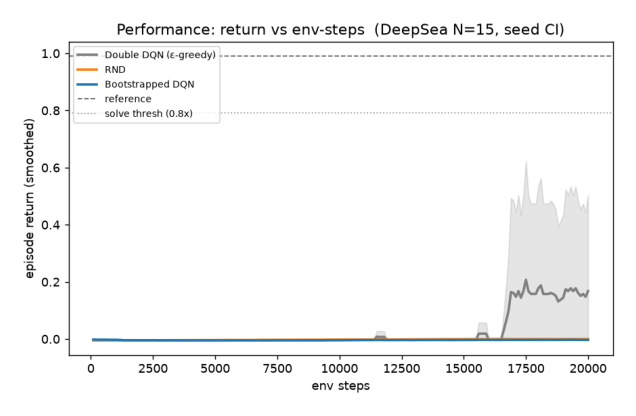

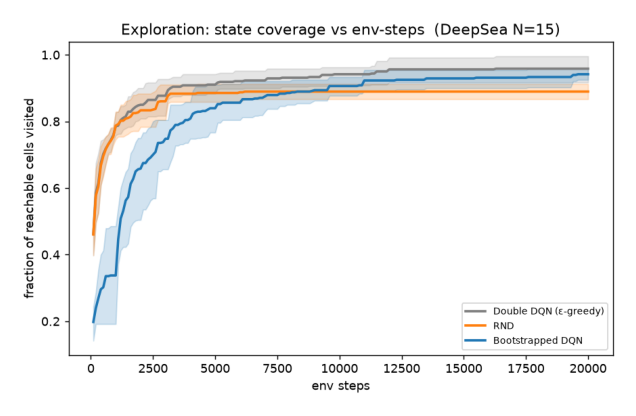

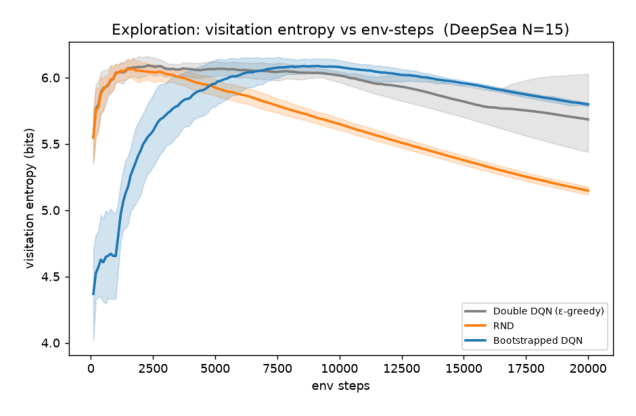

--- visitation heatmaps: results/noisy ---


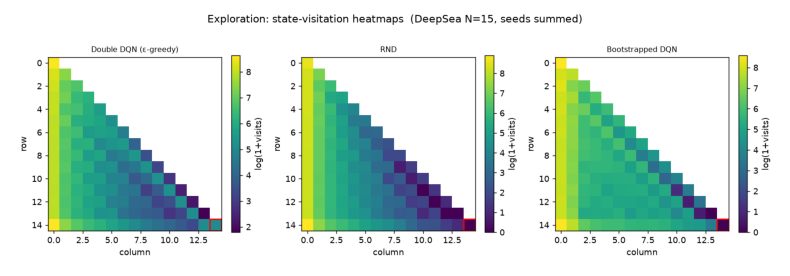

--- statistical rigor: results/noisy ---


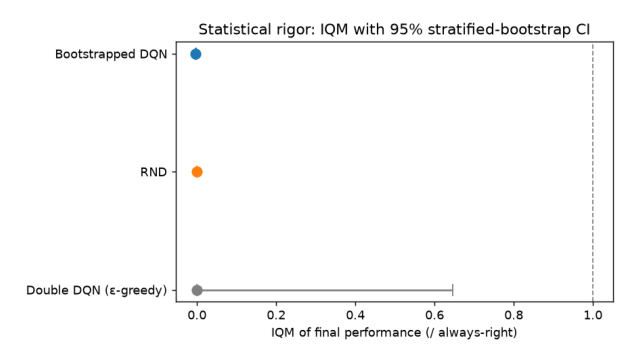

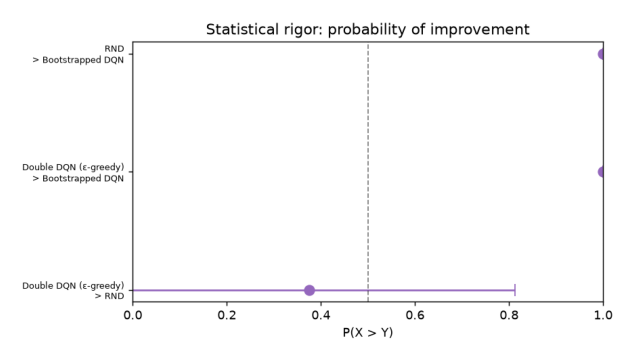

In [12]:
print("################  NOISY-TV DeepSea  ################")
hw_plots.show_learning_and_coverage("results/noisy")
hw_plots.show_heatmaps("results/noisy")
hw_plots.show_rigor("results/noisy")

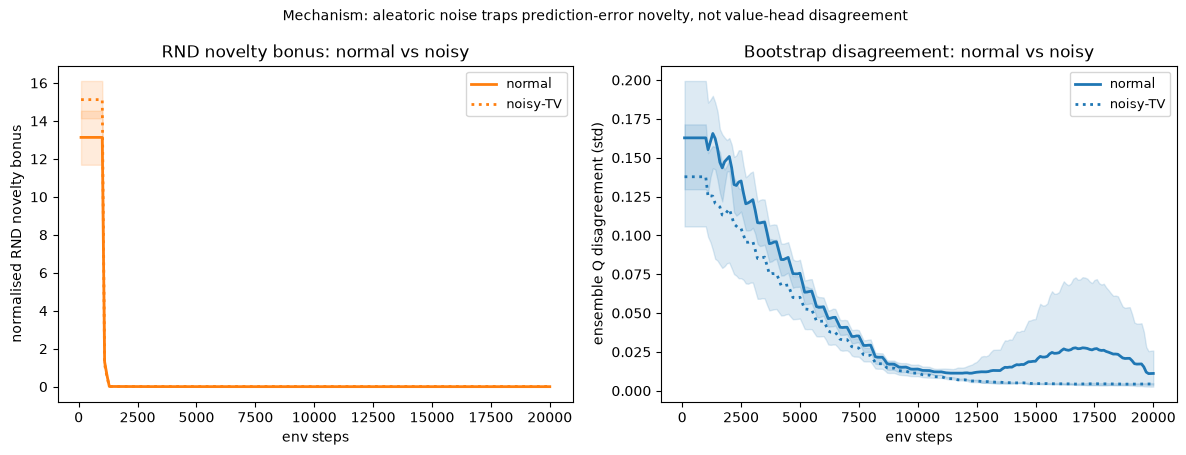

In [13]:
# Mechanism: the exploration-bonus signal of each agent, normal vs noisy.
hw_plots.show_mechanism("results")

## Section G — Analysis questions (30 pts)

Answer each from your own runs' figures and numbers. Each question's point value is
shown next to it.

**Q1 — Normal DeepSea (5 pts).** Using the learning curves, the first-visit-to-goal bars, and the IQM panel, which method finds the treasure sooner and which is more reliable across seeds — and how does the plain Double-DQN baseline compare? Quantify.

**Answer.** RND is the clear winner on the normal board in this run. It reached the goal in **4/4 seeds**, with first visits at 10,124, 10,499, 7,439, and 11,340 environment steps (mean **9,850.5**). It also crossed the 0.8-reference solve threshold in **4/4 seeds**, with a median of **16,950 steps**. Its final normalized-performance IQM was **0.694**, with bootstrap CI **[0.643, 0.726]**.

Bootstrapped DQN was less reliable with these hyperparameters and this 20k-step budget: it first reached the goal in **2/4 seeds** (mean among successful seeds **16,949.5 steps**) and crossed the solve threshold in only **1/4 seeds**, at 20,000 steps. Its IQM was only **0.0026**, with a very wide CI **[-0.0037, 0.591]**, reflecting strong seed dependence.

Plain Double DQN did not learn a reliable deep strategy. One lucky seed touched the goal at step 7,544, but only **1/4** seeds ever reached it, **0/4** crossed the solve threshold, and its final IQM stayed essentially zero (**-0.00036**). Thus a single early first visit does not mean that the policy learned the task; RND was both much more consistent and much stronger at the end.


**Q2 — Noisy TV (5 pts).** How does RND's behaviour change from the normal board to the noisy one? Reference its intrinsic-bonus curve (does it decay?) and its visitation heatmap.

**Answer.** The noisy-TV observation destroys RND's useful exploration behavior. On normal DeepSea, RND reached the goal in **4/4 seeds**, obtained full final coverage (**1.00**), visitation entropy about **6.52 bits**, and a final deepest-column fraction of about **0.859**. On the noisy board it reached the goal in **0/4 seeds**, final normalized performance returned to approximately zero, coverage fell to about **0.909**, entropy to about **5.16 bits**, and the final depth fraction collapsed to **0.021**.

The heatmap changes from broad visitation across the whole reachable triangle, including the right frontier, to a strongly left-heavy distribution concentrated around the noisy column 0. The recorded normalized RND bonus still drops sharply during early training, but its late residual is larger on the noisy board: approximately **0.010** over the last recorded updates versus about **0.001** on the normal board. Therefore the global average bonus mostly decays, yet the continually changing noisy observations keep a relatively persistent and misleading novelty signal at the left wall, preventing coherent progress toward the treasure.


**Q3 — Mechanism (6 pts).** Why does the noisy TV trap RND but not Bootstrapped DQN? Answer in terms of prediction error vs value-head disagreement (aleatoric vs epistemic uncertainty). What property of the noise is essential?

**Answer.** RND equates prediction error with novelty. A fresh noisy-TV observation is difficult to predict even after the agent has visited the same physical cell many times, so RND repeatedly treats that cell as new and assigns it intrinsic reward. This is **aleatoric uncertainty**: randomness inherent in the observation stream, not uncertainty that can be removed merely by learning more about the task. The bonus is therefore not aligned with information that improves the external-return policy.

Bootstrapped DQN instead explores through disagreement between value heads. The heads represent **epistemic uncertainty** about action values: disagreement is high where data have not pinned down the expected return, and it can shrink when transitions and rewards are observed. Since the TV noise is action-independent and has no effect on reward or dynamics, it should not systematically make one action more valuable; the heads can learn to ignore it rather than receiving a direct reward for unpredictability.

The essential property is that the noise is **fresh/stochastic, reward-irrelevant, and not controllably informative about the optimal action**. If the feature were stable, predictable, or correlated with useful reward information, it would not create the same RND trap.


**Q4 — Breadth vs depth (5 pts).** From coverage, entropy, and deepest-column-reached, describe each agent's exploration style. Can coverage look healthy while the goal is never reached?

**Answer.** RND on the normal board explores both broadly and deeply: it achieved **100% coverage**, about **6.52 bits** of entropy, and a final mean depth of roughly **12.1 of 14 columns**, reaching the goal in every seed. Bootstrapped DQN also covered much of the board (**96.9%**, about **6.25 bits**), but its depth was highly seed-dependent: the last-100-episode mean was about **5.45 columns** overall, with one seed reaching a strong right-going solution and others remaining shallow. Its style is coherent and episode-level, but which sampled hypothesis succeeds can vary substantially with only five heads and four seeds.

Double DQN's ε-greedy exploration produced apparently broad statistics—about **92.5% coverage** and **5.44 bits** of entropy—while its final behavior remained near the left edge (roughly **0.43 columns** over the last 100 episodes) and it failed to solve the task. The noisy RND result is an even clearer example: it retained about **90.9% coverage** but reached the goal in **0/4** seeds. Hence coverage can look healthy because many cells were touched at least once during random exploration, while the agent never discovers or commits to the complete temporally extended right-going sequence.


**Q5 — Rigor (5 pts).** Do the IQM CIs / probability-of-improvement support a *significant* difference at 4 seeds? What would strengthen the claim?

**Answer.** **Answer.** With only four seeds, the statistical results should be interpreted cautiously. On normal DeepSea, RND has a substantially higher IQM point estimate than Double DQN and Bootstrapped DQN. However, the 95% IQM interval of Bootstrapped DQN is extremely wide and overlaps the RND result. The probability-of-improvement panel reports approximately (P(\mathrm{RND}>\mathrm{Bootstrap})=0.75), with a broad interval of roughly ([0.25,1.0]). Therefore, the run provides strong empirical evidence that RND was more reliable under this particular budget, but it does not establish a statistically significant population-level advantage over Bootstrapped DQN.

On the noisy board, the IQM point estimates of RND and Bootstrapped DQN are both close to zero. Double DQN also has a near-zero point estimate but a wide confidence interval because one or more seeds perform much better than the others. The pairwise probability estimates are approximately (P(\mathrm{RND}>\mathrm{Bootstrap})=1.0), (P(\mathrm{Double\ DQN}>\mathrm{Bootstrap})=1.0), and (P(\mathrm{Double\ DQN}>\mathrm{RND})=0.375). These extreme estimates should not be interpreted as definitive significance because they are based on only four seeds and, in some comparisons, very small differences between near-zero scores.

A stronger conclusion would require more independent seeds, preferably at least 10–20, paired seeds across methods, a larger training budget, confidence intervals for all major metrics, and hyperparameters fixed before the final evaluation.


**Q6 — Practice (4 pts).** For a task with reward-irrelevant sensory noise (e.g. a flickering screen), which method would you choose, and why?

**Answer.** I would choose **Bootstrapped DQN with randomized priors** over plain RND when the observation contains reward-irrelevant flickering or sensory noise. Its exploration signal is value-head disagreement, which is intended to track reducible uncertainty about returns; action-independent noise does not directly earn intrinsic reward and can be ignored once its lack of value is learned. RND directly rewards predictor error, so unpredictable nuisance features can remain attractive even though they provide no task-relevant information. In practice I would also consider filtering or learning an invariant representation of the observation, and I would use multiple seeds because the bootstrap method was high-variance in this experiment.


## Section H — Export your submission

This writes **`submission.zip`** (< 10 MB): deterministic fingerprints of your
implementations plus the run records and summaries from the sweep. Submit it with the
notebook.

In [14]:
import hw_grading

out = hw_grading.export_artifacts(
    results_dir="results", out="submission.zip", student_number=STUDENT_NUMBER
)
print("submit this file alongside the notebook:", out)

wrote i:\دانشگاه\ترم 8\Deep RL\HW\hw_6\exploration_hw\submission.zip  (1.40 MB)  student_number=[student ID removed]
submit this file alongside the notebook: i:\دانشگاه\ترم 8\Deep RL\HW\hw_6\exploration_hw\submission.zip
